In [1]:
import copy
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader

from ddpm.data.das_dataset import DasDataset
from ddpm.diffusion.rad_noise_scheduler import RADNoiseScheduler
from ddpm.models.unet_rad import RAD
from ddpm.masks.rad_masks import random_rad_mask, channel_strip
from ddpm.diffusion.rad_inpainting import rad_inpaint
from ddpm.training.rad_training2 import train_rad
from ddpm.plotting.loss_plot import update_loss_plot

device="cuda" if torch.cuda.is_available() else "cpu"

das_data=Path("/datasets/training/earthquake/share/SISSLE_south30")
train_loader_earthquake=DataLoader(DasDataset([das_data/"train_1001.h5"]),batch_size=16,shuffle=True)
test_loader_earthquake=DataLoader(DasDataset([das_data/"test_1001.h5"]),batch_size=16,shuffle=False)

scheduler_rad=RADNoiseScheduler(ph1_steps=1000,ph2_steps=1000,beta_start=1e-4,beta_end=0.02,device=device)

checkpoints=Path("checkpoints")
checkpoint_meta={
    "base_channels":64,"channels_multiplier":(1,1,2,2,4),
    "normalization":{"function":"arcsinh","s":50.0,"A_max":12350.0},
    "model_key":"model_rad","optimizer_key":"optimizer_rad","train_loss_key":"train_losses","val_loss_key":"val_losses"
}

In [2]:
model_rad=RAD(in_channels=1,out_channels=1,base_channels=64,channels_multiplier=(1,1,2,2,4),nbr_rb=2,dropout=0.1).to(device)
optimizer_rad=torch.optim.Adam(model_rad.parameters(),lr=1e-4)

model_path_old=checkpoints/"das_rad_earthquake_model.pth"
model_path_v2=checkpoints/"das_rad_earthquake_model_v2.pth"
loss_plot_path_v2=checkpoints/"das_rad_earthquake_loss_v2.png"

if model_path_v2.exists():
    ckpt=torch.load(model_path_v2,map_location=device)
    model_rad.load_state_dict(ckpt["model_rad"])
    optimizer_rad.load_state_dict(ckpt["optimizer_rad"])
    ema_rad=copy.deepcopy(model_rad); ema_rad.load_state_dict(ckpt["ema_model_rad"])
    train_losses=ckpt.get("train_losses",[]); val_losses=ckpt.get("val_losses",[])
    start_epoch=ckpt["completed_epochs"]
    print("resuming v2 from epoch",start_epoch)
else:
    ckpt=torch.load(model_path_old,map_location=device)
    model_rad.load_state_dict(ckpt["model_rad"])
    optimizer_rad.load_state_dict(ckpt["optimizer_rad"])
    ema_rad=copy.deepcopy(model_rad)
    train_losses=[]; val_losses=[]
    start_epoch=ckpt.get("completed_epochs",40)
    print("starting v2 from old checkpoint, epoch",start_epoch)

resuming v2 from epoch 53


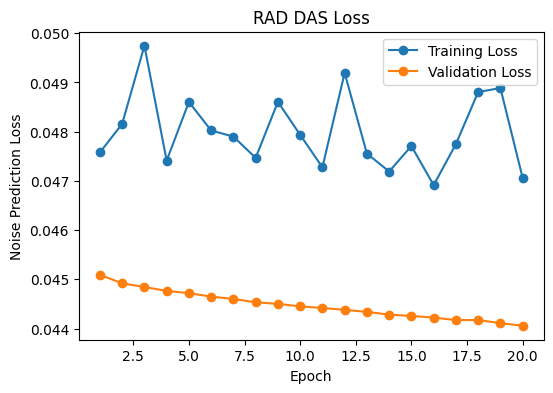

In [3]:
epochs=60   # total; 20 more epochs after 40

train_losses,val_losses,ema_rad=train_rad(
    model=model_rad,
    train_loader=train_loader_earthquake,
    val_loader=test_loader_earthquake,
    scheduler=scheduler_rad,
    optimizer=optimizer_rad,
    device=device,
    epochs=epochs,
    checkpoint_path=model_path_v2,
    model_key="model_rad",
    optimizer_key="optimizer_rad",
    train_loss_key="train_losses",
    val_loss_key="val_losses",
    start_epoch=start_epoch,
    train_losses=train_losses,
    val_losses=val_losses,
    checkpoint_meta=checkpoint_meta,
    plot_function=update_loss_plot,
    loss_plot_path=loss_plot_path_v2,
    ema_model=ema_rad,
    ema_decay=0.999,
    phase1_prob=0.75,
    masked_loss=True
)

In [8]:
def collect_hole_rows(model,loader,n_batches=3,seed=0):
    g=torch.Generator(device=device).manual_seed(seed)
    T=[];G=[]
    for k,batch in enumerate(loader):
        if k>=n_batches: break
        x0=batch.to(device); B,C,H,W=x0.shape
        mask=channel_strip(B,H,W,device,generator=g)
        res,_,_=rad_inpaint(model=model,scheduler=scheduler_rad,x0=x0,mask=mask,device=device,generator=g)
        rows=(mask[:,0,:,0]==0)
        T.append(x0[:,0][rows].cpu()); G.append(res[:,0][rows].cpu())
    return torch.cat(T),torch.cat(G)

def psd(x): return (torch.fft.rfft(x,dim=-1).abs()**2).mean(0)

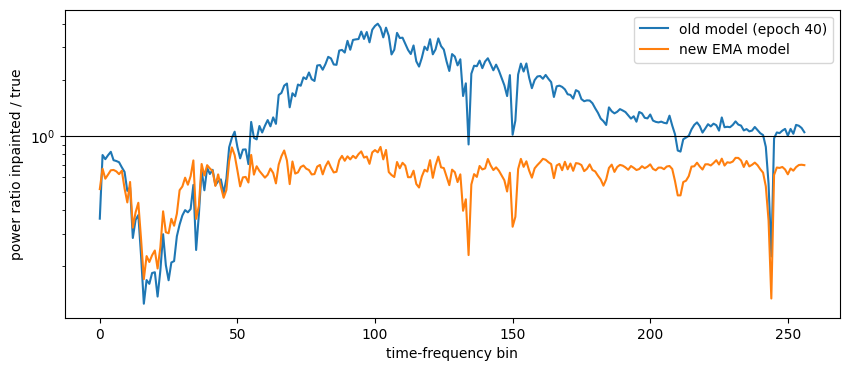

old | amplitude ratio inpainted/true at 50/90/99%: [1.356 1.058 0.93 ]
new | amplitude ratio inpainted/true at 50/90/99%: [0.801 0.704 0.778]


In [9]:
model_old=copy.deepcopy(model_rad)
model_old.load_state_dict(torch.load(model_path_old,map_location=device)["model_rad"])
model_old.eval()

T_old,G_old=collect_hole_rows(model_old,test_loader_earthquake)
T_new,G_new=collect_hole_rows(ema_rad,test_loader_earthquake)

plt.figure(figsize=(10,4))
plt.semilogy(psd(G_old)/psd(T_old),label="old model (epoch 40)")
plt.semilogy(psd(G_new)/psd(T_new),label="new EMA model")
plt.axhline(1,color="k",lw=0.8)
plt.xlabel("time-frequency bin"); plt.ylabel("power ratio inpainted / true"); plt.legend()
plt.show()

for name,T,G in [("old",T_old,G_old),("new",T_new,G_new)]:
    p=[np.percentile(G.abs().numpy(),q)/np.percentile(T.abs().numpy(),q) for q in [50,90,99]]
    print(name,"| amplitude ratio inpainted/true at 50/90/99%:",np.round(p,3))

In [10]:
'''inference using only phase 1: old model (epoch 40) vs. new EMA model'''
from ddpm.diffusion.rad_inpainting import rad_inpaint
from ddpm.masks.rad_masks import random_rad_mask

x0=next(iter(test_loader_earthquake))[:2].to(device)
B,C,H,W=x0.shape

g=torch.Generator(device=device).manual_seed(1)
mask=random_rad_mask(B,H,W,device,generator=g)     # same mask for both models

shown=[999,750,500,250,100,0]

g_old=torch.Generator(device=device).manual_seed(0)
result_old,x_start,steps_old=rad_inpaint(model=model_old,scheduler=scheduler_rad,x0=x0,mask=mask,device=device,generator=g_old,timesteps_shown=shown)

g_new=torch.Generator(device=device).manual_seed(0)
result_new,_,steps_new=rad_inpaint(model=ema_rad,scheduler=scheduler_rad,x0=x0,mask=mask,device=device,generator=g_new,timesteps_shown=shown)

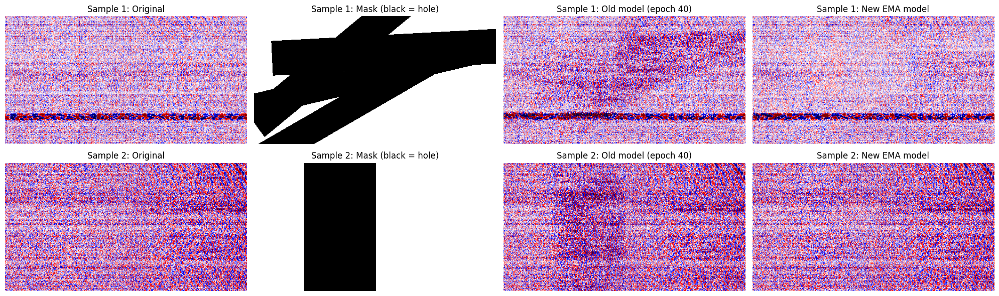

In [11]:
import matplotlib.pyplot as plt

w=0.5   

fig,axes=plt.subplots(2,4,figsize=(20,6))
for i in range(2):
    panels=[(x0[i,0],"Original"),
            (mask[i,0],"Mask (black = hole)"),
            (result_old[i,0],"Old model (epoch 40)"),
            (result_new[i,0],"New EMA model")]
    for j,(img,title) in enumerate(panels):
        img=img.detach().cpu()
        if j==1: axes[i,j].imshow(img,aspect="auto",cmap="gray")
        else:    axes[i,j].imshow(img,aspect="auto",cmap="seismic",vmin=-w,vmax=w)
        axes[i,j].set_title(f"Sample {i+1}: {title}")
        axes[i,j].axis("off")
plt.tight_layout()
plt.show()

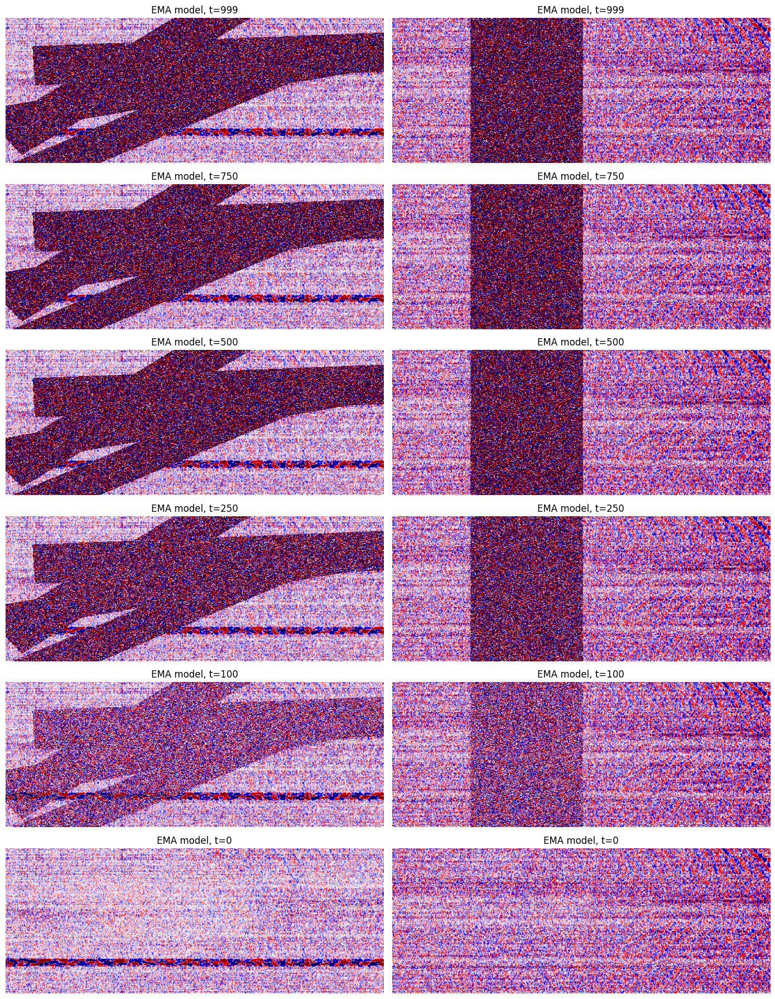

In [12]:
steps=list(steps_new.keys())
fig,axes=plt.subplots(len(steps),2,figsize=(14,3*len(steps)))
for row,step in enumerate(steps):
    for i in range(2):
        sample=steps_new[step][i,0].detach().cpu()
        axes[row,i].imshow(sample,aspect="auto",cmap="seismic",vmin=-w,vmax=w)
        axes[row,i].axis("off")
        axes[row,i].set_title(f"EMA model, t={step}")
plt.tight_layout()
plt.show()